# Vision — VQA (Tanya-Jawab tentang Gambar)
**Kapan dipakai:** tiap baris = satu gambar + satu pertanyaan ("berapa orang?", "apakah ada
mobil?", "apa warna baju?") dan jawabannya singkat (yes/no, angka, kata).

**Langkah:** model VQA pretrained ViLT (470 MB, `vilt-b32-finetuned-vqa`, jawaban dipilih dari
3129 kata/angka) menjawab langsung tanpa dilatih. Alternatif murah (sel `#`): CLIP zero-shot,
pertanyaan diubah jadi beberapa kalimat jawaban kandidat, ambil yang paling cocok.

**Catatan:** model berbahasa Inggris. Pertanyaan Indonesia → terjemahkan dulu ke Inggris.

**Data demo:** 63 pertanyaan dari foto Penn-Fudan (hitung orang) dan COCO8 (ada/tidak ada).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import torch
from PIL import Image
from sklearn.metrics import accuracy_score
from transformers import CLIPModel, CLIPProcessor, ViltForQuestionAnswering, ViltProcessor

## Konfigurasi

In [2]:
DATA_FOLDER = "../../../data_latihan/vision/vqa_demo"   # GANTI saat lomba
QUESTIONS_CSV = f"{DATA_FOLDER}/pertanyaan.csv"
KEY_CSV = f"{DATA_FOLDER}/pertanyaan_kunci.csv"   # hanya ada di data latihan
IMAGE_FOLDER = f"{DATA_FOLDER}/gambar"
VILT_FOLDER = "../../../pretrained/vilt_vqa"
CLIP_FOLDER = "../../../pretrained/clip_b32"

IMAGE_COL = "gambar"        # nama file gambar di IMAGE_FOLDER
QUESTION_COL = "pertanyaan"
DEVICE = "cpu"
if torch.cuda.is_available():
    DEVICE = "cuda"

## Baca data

In [3]:
test = pd.read_csv(QUESTIONS_CSV)
print(test.shape)
test.head(8)

(63, 3)


,id,gambar,pertanyaan
0,1,000000000009.jpg,Is there a suitcase in the picture?
1,2,000000000034.jpg,Is there a zebra in the picture?
2,3,000000000061.jpg,Is there a tie in the picture?
3,4,000000000036.jpg,Is there a person in the picture?
4,5,PennPed00060.jpg,How many people are in the picture?
5,6,PennPed00067.jpg,How many people are in the picture?
6,7,PennPed00048.jpg,How many people are in the picture?
7,8,000000000030.jpg,Is there a potted plant in the picture?


## Model ViLT + jawab satu pertanyaan
`logits` = skor tiap jawaban yang mungkin. Jawaban = skor tertinggi. Skor lewat sigmoid dipakai
sebagai keyakinan (0–1).

In [4]:
processor = ViltProcessor.from_pretrained(VILT_FOLDER, local_files_only=True)
model = ViltForQuestionAnswering.from_pretrained(VILT_FOLDER, local_files_only=True)
model = model.to(DEVICE)
model.eval()


def answer(image_name, question):
    image = Image.open(f"{IMAGE_FOLDER}/{image_name}").convert("RGB")
    encoded = processor(image, question, return_tensors="pt").to(DEVICE)
    with torch.no_grad():
        logits = model(**encoded).logits
    best = logits.argmax(-1).item()
    confidence = torch.sigmoid(logits[0, best]).item()
    return model.config.id2label[best], confidence


print(test.loc[0, QUESTION_COL], "->", answer(test.loc[0, IMAGE_COL], test.loc[0, QUESTION_COL]))

Loading weights:   0%|          | 0/212 [00:00<?, ?it/s]

Is there a suitcase in the picture? -> ('no', 0.9986503720283508)


## Jawab semua pertanyaan
Keyakinan rendah = jawaban layak dicek manual atau diganti jawaban default.

In [5]:
answers = []
confidences = []
for image_name, question in zip(test[IMAGE_COL], test[QUESTION_COL]):
    reply, confidence = answer(image_name, question)
    answers.append(reply)
    confidences.append(confidence)
answer_counts = pd.Series(answers).value_counts()
print(answer_counts.head(10))

yes    13
no     10
1      10
2       9
5       6
8       4
3       3
4       2
7       2
6       1
Name: count, dtype: int64


## Contoh jawaban

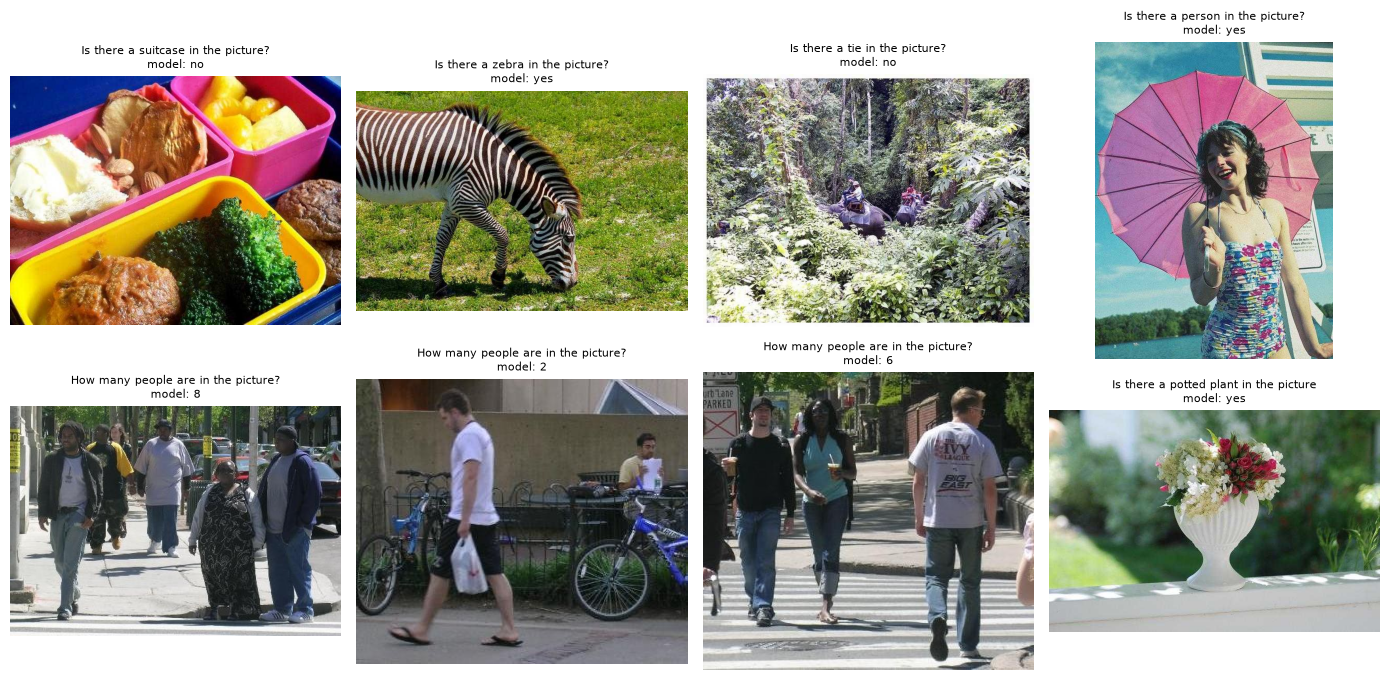

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for number in range(8):
    ax = axes[number // 4, number % 4]
    ax.imshow(Image.open(f"{IMAGE_FOLDER}/{test.loc[number, IMAGE_COL]}"))
    ax.axis("off")
    title = test.loc[number, QUESTION_COL][:38] + "\nmodel: " + answers[number]
    ax.set_title(title, fontsize=8)
plt.tight_layout()
plt.savefig("contoh_vqa.png", dpi=110)
plt.show()

## Submission

In [7]:
submission = pd.DataFrame()
submission["id"] = test["id"]
submission["jawaban"] = answers
submission.to_csv("submission.csv", index=False)
submission.head()

,id,jawaban
0,1,no
1,2,yes
2,3,no
3,4,yes
4,5,8


## Cek dengan kunci jawaban latihan (HAPUS saat lomba)
Akurasi dipisah per jenis pertanyaan. Menghitung biasanya jauh lebih sulit daripada ya/tidak.

In [8]:
test_key = pd.read_csv(KEY_CSV)
check = pd.DataFrame()
check["jenis"] = test_key["jenis"]
check["jawaban_asli"] = test_key["jawaban"]
check["tebakan"] = answers
check["benar"] = check["jawaban_asli"] == check["tebakan"]
print("akurasi semua:", round(accuracy_score(test_key["jawaban"], answers), 3))
print(check.groupby("jenis")["benar"].agg(["mean", "count"]))

# menghitung: selisih 1 orang masih dianggap dekat
counting = check[check["jenis"] == "hitung"].copy()
counting["selisih"] = counting["tebakan"].astype(int) - counting["jawaban_asli"].astype(int)
print("hitung, selisih rata-rata:", round(counting["selisih"].abs().mean(), 2))

akurasi semua: 0.619
            mean  count
jenis                  
ada     0.913043     23
hitung  0.450000     40
hitung, selisih rata-rata: 1.55


## Alternatif: CLIP zero-shot untuk soal menghitung (kandidat 1..6)
Hapus `#` di semua baris untuk memakai. Dinilai pada baris "hitung" dari sel kunci di atas.

In [9]:
# clip = CLIPModel.from_pretrained(CLIP_FOLDER, local_files_only=True)
# clip = clip.to(DEVICE)
# clip.eval()
# clip_processor = CLIPProcessor.from_pretrained(CLIP_FOLDER, local_files_only=True)
# CANDIDATES = ["1", "2", "3", "4", "5", "6"]
# sentences = []
# for number_text in CANDIDATES:
#     sentences.append("a photo of " + number_text + " people")
# clip_correct = 0
# for row in counting.index:
#     image = Image.open(f"{IMAGE_FOLDER}/{test.loc[row, IMAGE_COL]}").convert("RGB")
#     encoded = clip_processor(text=sentences, images=image, return_tensors="pt", padding=True)
#     with torch.no_grad():
#         scores = clip(**encoded.to(DEVICE)).logits_per_image
#     if CANDIDATES[scores.argmax().item()] == str(test_key.loc[row, "jawaban"]):
#         clip_correct = clip_correct + 1
# print("akurasi CLIP (hitung):", round(clip_correct / len(counting), 3))